# 🌀 K-Means Clustering

K-Means adalah model **unsupervised** — tidak ada jawaban benar yang diberitahu ke model.
Model hanya diberi ukuran kelopak, lalu diminta **mengelompokkan sendiri** bunga yang mirip.

**Studi kasus:** mengelompokkan 150 bunga iris **tanpa label spesies**.

| Fitur | Arti |
|---|---|
| `sepal_length` | panjang kelopak luar (cm) |
| `sepal_width` | lebar kelopak luar (cm) |
| `petal_length` | panjang kelopak dalam (cm) |
| `petal_width` | lebar kelopak dalam (cm) |

**Target:** tidak ada! Kolom `species` sengaja kita **buang** — itulah bedanya dengan
decision tree, yang belajar dari label. Di sini model mencari polanya sendiri.

Alur notebook:

1. Memuat data & membuang label
2. Memilih jumlah klaster (`k`) dengan metode *elbow*
3. Melatih model K-Means
4. Melihat hasil klaster & titik pusatnya (*centroid*)
5. Mengecek hasilnya terhadap label asli

> 💡 **Jalankan setiap sel** dengan memilihnya dan tekan `Shift + Enter`.

---
## 0️⃣ Setup & Import

K-Means juga sudah tersedia di scikit-learn sebagai `KMeans`.

> 📦 Jika scikit-learn belum terinstall: `uv add scikit-learn` atau `pip install scikit-learn`

In [1]:
# ── Import pustaka ──
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans

%matplotlib inline

# ── Warna & gaya grafik ──
# Satu warna per klaster — dipakai konsisten di semua grafik.
WARNA_KLASTER = {0: "#2a78d6", 1: "#eb6834", 2: "#1baf7a"}
BIRU, ORANYE = "#2a78d6", "#eb6834"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "text.color": "#0b0b0b", "xtick.color": "#898781", "ytick.color": "#898781",
    "grid.color": "#e1e0d9", "axes.grid": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110,
})

import sklearn
print(f"scikit-learn version : {sklearn.__version__}")
print(f"NumPy version        : {np.__version__}")
print(f"Pandas version       : {pd.__version__}")

scikit-learn version : 1.9.1
NumPy version        : 2.5.3
Pandas version       : 3.0.6


---
## 1️⃣ Memuat Dataset

Dataset `iris.csv` sama seperti notebook decision tree: 150 bunga iris yang sudah diukur.
Bedanya, kali ini labelnya tidak kita pakai.

In [2]:
# ── Membaca CSV ──
df = pd.read_csv("data/iris.csv")
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]

FITUR = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

print(f"Shape (baris, kolom) : {df.shape}")
print(f"Nama kolom           : {list(df.columns)}")

Shape (baris, kolom) : (150, 5)
Nama kolom           : ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


In [3]:
# ── 5 baris pertama ──
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


---
## 2️⃣ Membuang Label

Ini langkah paling penting di clustering: **model tidak boleh melihat `species`.**

Kolomnya kita simpan dulu di variabel terpisah, bukan untuk dilatih, tapi untuk
**mengecek** di akhir apakah klaster yang terbentuk memang masuk akal.

In [4]:
# ── Pisahkan label dari fitur ──
label_asli = df["species"]   # hanya untuk verifikasi di bagian 6️⃣ — TIDAK dipakai model
X = df[FITUR]                # yang dilihat model: ukuran kelopak saja

print(f"X shape : {X.shape}  → {X.shape[0]} bunga, {X.shape[1]} fitur")
print(f"Kolom yang dipakai model : {list(X.columns)}")
print(f"Kolom yang dibuang       : ['species']")

X shape : (150, 4)  → 150 bunga, 4 fitur
Kolom yang dipakai model : ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
Kolom yang dibuang       : ['species']


In [5]:
# ── Statistik deskriptif fitur ──
X.describe().round(2)

,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


---
## 3️⃣ Memilih Jumlah Klaster (`k`)

K-Means **harus diberi tahu** mau berapa klaster. Kalau salah pilih, hasilnya bisa aneh.

Cara paling sederhana untuk memilihnya: **metode elbow**. Kita coba `k = 1` sampai `10`, lalu
lihat *inertia* — total jarak semua titik ke centroid klasternya. Makin banyak klaster, makin
kecil inertia-nya. Kita cari titik di mana penurunannya mulai **melandai** — bentuknya seperti siku.

In [6]:
# ── Hitung inertia untuk beberapa nilai k ──
daftar_k = range(1, 11)
inertia = []

for k in daftar_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    inertia.append(km.inertia_)

pd.DataFrame({"k": list(daftar_k), "inertia": np.round(inertia, 1)})

,k,inertia
0,1,681.4
1,2,152.3
2,3,78.9
3,4,57.2
4,5,46.5
5,6,39.0
6,7,34.3
7,8,30.1
8,9,28.3
9,10,26.0


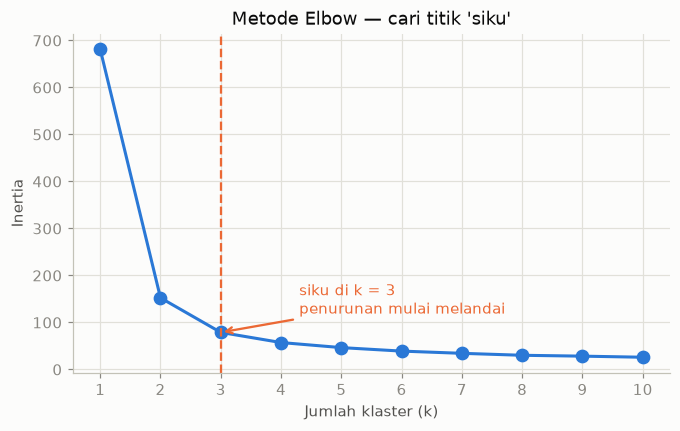

In [7]:
# ── Grafik elbow ──
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(list(daftar_k), inertia, marker="o", color=BIRU, linewidth=2, markersize=8)
ax.axvline(3, color=ORANYE, linestyle="--", linewidth=1.5)
ax.annotate(
    "siku di k = 3\npenurunan mulai melandai",
    xy=(3, inertia[2]), xytext=(4.3, inertia[2] + 40),
    color=ORANYE, fontsize=10,
    arrowprops=dict(arrowstyle="->", color=ORANYE, linewidth=1.5),
)

ax.set_xlabel("Jumlah klaster (k)")
ax.set_ylabel("Inertia")
ax.set_title("Metode Elbow — cari titik 'siku'")
ax.set_xticks(list(daftar_k))
plt.show()

Grafiknya turun tajam sampai `k = 3`, lalu melandai. Artinya **tiga klaster sudah cukup** —
menambah klaster keempat tidak banyak membantu.

> 🌸 Kebetulan (atau tidak) iris memang punya 3 spesies. Tapi ingat: model **tidak tahu** itu.
> Ia hanya melihat angkanya.

---
## 4️⃣ Melatih Model K-Means

Melatihnya hanya **dua baris**. Model akan menaruh 3 centroid secara acak, lalu mengulang dua
langkah sampai stabil:

1. **Assign** — setiap bunga dimasukkan ke centroid terdekat
2. **Update** — centroid digeser ke rata-rata anggotanya

In [8]:
# ── Latih model K-Means dengan k = 3 ──
model = KMeans(n_clusters=3, random_state=42, n_init=10)
model.fit(X)

klaster = model.labels_          # nomor klaster tiap bunga (0, 1, atau 2)

print("Model selesai dilatih ✓")
print(f"Jumlah klaster : {model.n_clusters}")
print(f"Inertia        : {model.inertia_:.1f}")
print(f"\nJumlah bunga per klaster:")
print(pd.Series(klaster).value_counts().sort_index())

Model selesai dilatih ✓
Jumlah klaster : 3
Inertia        : 78.9

Jumlah bunga per klaster:
0    62
1    50
2    38
Name: count, dtype: int64


### Titik pusat klaster (*centroid*)

Centroid adalah "bunga rata-rata" dari tiap klaster. Angka inilah yang bisa kita baca sebagai
ciri khas kelompoknya.

In [9]:
# ── Centroid tiap klaster ──
centroid = pd.DataFrame(model.cluster_centers_, columns=FITUR)
centroid.index = [f"klaster {i}" for i in range(model.n_clusters)]
centroid.round(2)

,sepal_length,sepal_width,petal_length,petal_width
klaster 0,5.90,2.75,4.39,1.43
klaster 1,5.01,3.43,1.46,0.25
klaster 2,6.85,3.07,5.74,2.07


---
## 5️⃣ Visualisasi Hasil Klaster

Kita gambar dua fitur yang paling jelas memisahkan kelompok: `petal_length` dan `petal_width`.
Tanda **✕** adalah centroid-nya.

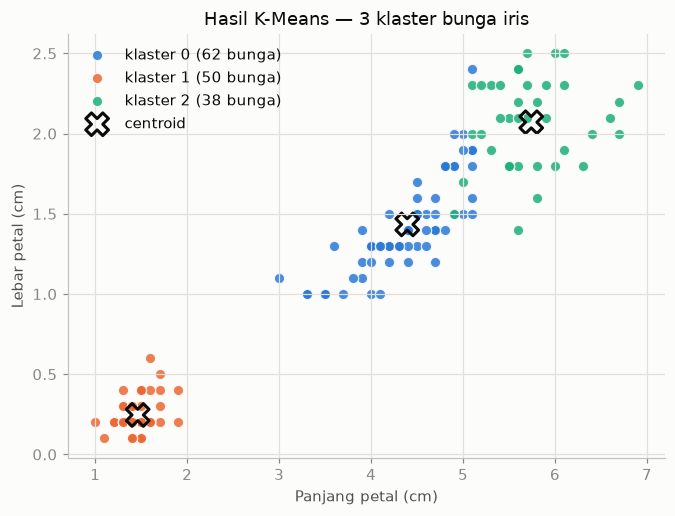

In [10]:
# ── Sebaran bunga per klaster ──
fig, ax = plt.subplots(figsize=(7, 5))

for i in range(model.n_clusters):
    anggota = X[klaster == i]
    ax.scatter(
        anggota["petal_length"], anggota["petal_width"],
        s=45, color=WARNA_KLASTER[i], alpha=0.85,
        edgecolor="#fcfcfb", linewidth=0.8,      # celah tipis antar titik
        label=f"klaster {i} ({len(anggota)} bunga)",
    )

# Centroid
ax.scatter(
    model.cluster_centers_[:, 2], model.cluster_centers_[:, 3],
    s=220, marker="X", color="none", edgecolor="#0b0b0b", linewidth=2,
    label="centroid",
)

ax.set_xlabel("Panjang petal (cm)")
ax.set_ylabel("Lebar petal (cm)")
ax.set_title("Hasil K-Means — 3 klaster bunga iris")
ax.legend(frameon=False, loc="upper left")
plt.show()

Terlihat jelas: K-Means berhasil memisahkan satu kelompok kecil di kiri bawah, dan dua kelompok
besar di kanan. Tapi dua kelompok di kanan itu **berdempetan** — di situlah batasnya tidak
sejelas decision tree yang punya label.

---
## 6️⃣ Cek Hasil terhadap Label Asli

Model tidak pernah melihat `species`, tapi kita masih menyimpannya. Sekarang saatnya
membandingkan: apakah klaster yang terbentuk **sejalan** dengan spesies sebenarnya?

In [11]:
# ── Bandingkan klaster dengan spesies asli ──
tabel = pd.crosstab(
    label_asli, klaster,
    rownames=["spesies asli"], colnames=["klaster"],
)
tabel

klaster,0,1,2
spesies asli,,,
Setosa,0,50,0
Versicolor,48,0,2
Virginica,14,0,36


Hasilnya rapi:

| Klaster | Isinya |
|---|---|
| 0 | Setosa (50 bunga) — kelompok paling kiri di grafik |
| 1 | Versicolor (48) + 2 Virginica |
| 2 | Virginica (48) + 2 Versicolor |

Jadi K-Means **menemukan sendiri** ketiga spesies itu tanpa pernah diberi tahu — hanya dari
ukuran kelopaknya. Dua bunga yang "nyasar" adalah yang ukurannya memang di perbatasan.